In [2]:
import os
from urllib.request import urlretrieve
import gzip
import matplotlib.pyplot as plt
import numpy as np
from pyteomics import fasta, parser, mass, achrom, electrochem, auxiliary
import pandas as pd
import json

truths = pd.read_csv('/home/callum/sno_data/processed/yang/yang_processed.csv')  # or however you load it
truths = truths.head(30)
#print(truths.iloc[:,0])
predicted = pd.read_csv("/home/callum/predictors/plmsno/pLMSNOSite/results.csv")

predicted["id"] = predicted["prot_desc"].str.split("|").str[1]

df_pred = predicted[["id", "position", "prediction"]]
print(df_pred.head())
print(len(df_pred))



       id  position  prediction
0  P05023        93           0
1  P05023       111           0
2  P05023       145           0
3  P05023       211           1
4  P05023       249           1
141


In [11]:
# path to proteome fasta
proteome = "~human_proteome/proteome.gz"



c_dict = {}

with gzip.open('/home/callum/human_proteome/proteome.gz', mode='rt') as gzfile:
    subset = []
    counter = 0
    for description, sequence in fasta.FASTA(gzfile):
        c_list = []

        parts = description.split("|")
        id = parts[1]

        for index, i in enumerate(sequence):
            if i == "C":
                c_list.append(index + 1)
                
                # print(sequence.index(i))


        c_dict[id] = c_list

            

        # counter += 1
        # if counter > 5:
        #     break

print(f"length of dict (protein entries):{len(c_dict)}")





# creating df from proteome dict 
all_sites = pd.DataFrame(
    [(prot, pos) for prot, positions in c_dict.items() for pos in positions],
    columns=["id", "position"],
)    

with open("/home/callum/human_proteome/proteome_dict.json", "w") as f:
    json.dump(c_dict, f)
    f.close()



# load positive sites in
pos = pd.read_csv("/home/callum/sno_data/processed/yang/yang_processed.csv")

# merge with proteome dict to get all negatives 
pos_u = pos[["id", "position"]].drop_duplicates()

df = (
    all_sites[all_sites["id"].isin(pos_u["id"])]   # keep only proteins that are in yang
    .merge(pos_u, on=["id", "position"], how="left", indicator=True)
)

df["modified"] = (df["_merge"] == "both").astype(int)
df = df.drop(columns="_merge")

#print(df[df["modified"]==1].head())


print(f"length of final merged df: {len(df)}")
print(f"length of yang (positive sites): {len(pos)}")
print(f"proteins in yang: {pos["id"].nunique()}")
print(f"proteins in final df (should be 978): {df["id"].nunique()}")

print(df["modified"].value_counts())

print(df.head())



length of dict (protein entries):20652
length of final merged df: 17062
length of yang (positive sites): 1647
proteins in yang: 978
proteins in final df (should be 978): 969
modified
0    15451
1     1611
Name: count, dtype: int64
       id  position  modified
0  P30405         6         0
1  P30405        30         0
2  P30405        82         1
3  P30405       104         0
4  P30405       157         0


In [12]:
#print(df.shape == df_pred.shape)

pred = pd.read_csv("/home/callum/predictors/plmsno/pLMSNOSite/output/yang/yang_results.csv")

print(df.shape)
print(pred.shape)

(17062, 3)
(17062, 5)


In [25]:
#pred["id"] = pred["prot_desc"].split("|")[1]
pred["id"] = pred["prot_desc"].str.split("|").str[1]
#print(pred.head)
pred_final = pred[["id", "position", "prediction"]]

names = ["id", "position", "modified"]
pred_final.columns = names
print(pred_final.shape == df.shape)


True


In [ ]:
# I have 2 dataframes - one is experimentally determined sites and the other is predicted sites using a predictive tool. they are called pred_final and df respectively. the columns are ["id", "position", "modified"]. I want to assess the performance of the model on these experimentally determined sites. can you give me code that evaluates the key metric and gives summary statistics

           id  position      organism
0  A0A024RBG1       132  Homo sapiens
1  A0A075B759        62  Homo sapiens
2  A0A075B767        62  Homo sapiens
3  A0A0B4J2A2        62  Homo sapiens
4  A0A0G2JMZ2      1039  Homo sapiens
11732


In [ ]:
# Yang et al - AD brain data
# plmSNO predictor 

In [ ]:
import pandas as pd
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score,
    matthews_corrcoef, balanced_accuracy_score
)


predicted = pred_final[["id", "position", "modified"]].rename(columns={"modified": "pred_label"})
experimental    = df[["id", "position", "modified"]].rename(columns={"modified": "true_label"})

print("Experimental table:", experimental.shape)
print("Predicted table:   ", predicted.shape)

# ---------------------------------------------------------------
# STEP 2: Merge on protein id + position
# ---------------------------------------------------------------
# how="outer" keeps sites that appear in only one table.
# indicator=True adds a "_merge" column telling you where each row came from.
merged = experimental.merge(predicted, on=["id", "position"], how="outer", indicator=True)

print("\nWhere did each site come from?")
print(merged["_merge"].value_counts())
# left_only  = in experimental table only (the tool never scored this site)
# right_only = in predicted table only (the tool scored it, no experimental entry)
# both       = in both tables

# ---------------------------------------------------------------
# STEP 3: Fill gaps
# ---------------------------------------------------------------
# A site missing from one table gets 0 (not modified / not predicted).
# NOTE: this assumes "absent from experiments" means "not modified".
# If your experimental table only lists positives, see the caveat below.
merged["true_label"] = merged["true_label"].fillna(0).astype(int)
merged["pred_label"] = merged["pred_label"].fillna(0).astype(int)

# OPTIONAL: restrict to proteins present in BOTH tables, which is fairer
# because it removes proteins the tool was never run on.
# shared_ids = set(experimental["id"]) & set(predicted["id"])
# merged = merged[merged["id"].isin(shared_ids)]

y_true = merged["true_label"]
y_pred = merged["pred_label"]

# ---------------------------------------------------------------
# STEP 4: Confusion matrix
# ---------------------------------------------------------------
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

print("\n=== CONFUSION MATRIX COUNTS ===")
print(f"True positives  (TP): {tp}  -> predicted modified AND experimentally modified")
print(f"False positives (FP): {fp}  -> predicted modified but NOT experimentally modified")
print(f"False negatives (FN): {fn}  -> experimentally modified but the tool MISSED it")
print(f"True negatives  (TN): {tn}  -> predicted unmodified AND not experimentally modified")
print(f"Total sites evaluated: {tp + fp + fn + tn}")

# ---------------------------------------------------------------
# STEP 5: Metrics
# ---------------------------------------------------------------
precision   = precision_score(y_true, y_pred, zero_division=0)
recall      = recall_score(y_true, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
f1          = f1_score(y_true, y_pred, zero_division=0)
bal_acc     = balanced_accuracy_score(y_true, y_pred)
mcc         = matthews_corrcoef(y_true, y_pred)

print("\n=== PERFORMANCE METRICS ===")
print(f"Precision          : {precision:.3f}  (of sites the tool called modified, fraction that were real) = TP / (TP + FP)")
print(f"Recall/Sensitivity : {recall:.3f}  (of real modified sites, fraction the tool found) = TP / (TP + FN)")
print(f"Specificity        : {specificity:.3f}  (of unmodified sites, fraction correctly called unmodified) = TN / (TN + FP)")
print(f"F1 score           : {f1:.3f}  (harmonic mean of precision and recall)")
print(f"Balanced accuracy  : {bal_acc:.3f}  (mean of recall and specificity; robust to class imbalance)")
print(f"MCC                : {mcc:.3f}  (-1 to +1; 0 = random; best single number for imbalanced data)")

# ---------------------------------------------------------------
# STEP 6: Per-protein breakdown
# ---------------------------------------------------------------
# Flag each row's outcome, then sum per protein.
merged["is_TP"] = ((merged["true_label"] == 1) & (merged["pred_label"] == 1)).astype(int)
merged["is_FP"] = ((merged["true_label"] == 0) & (merged["pred_label"] == 1)).astype(int)
merged["is_FN"] = ((merged["true_label"] == 1) & (merged["pred_label"] == 0)).astype(int)

per_protein = merged.groupby("id").agg(
    n_experimental_sites=("true_label", "sum"),
    n_predicted_sites=("pred_label", "sum"),
    TP=("is_TP", "sum"),
    FP=("is_FP", "sum"),
    FN=("is_FN", "sum"),
)

# Per-protein recall (NaN where a protein has no experimental sites)
per_protein["recall"] = per_protein["TP"] / per_protein["n_experimental_sites"].where(per_protein["n_experimental_sites"] > 0)

print("\n=== PER-PROTEIN TABLE (first rows) ===")
print(per_protein.head())

print("\n=== SUMMARY STATISTICS ACROSS PROTEINS ===")
print(per_protein.describe().round(3))

Experimental table: (17062, 3)
Predicted table:    (17062, 3)


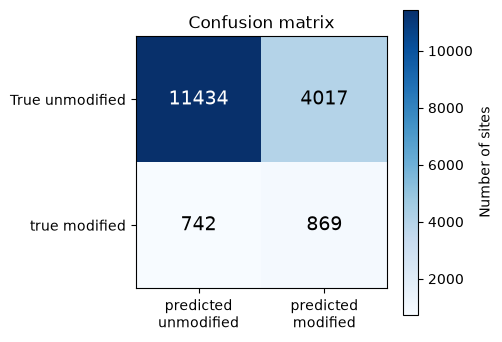

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

y_true = merged["true_label"]
y_pred = merged["pred_label"]

cm = np.array([[tn, fp],
               [fn, tp]])

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels([f"predicted\nunmodified", f"predicted\nmodified"])
ax.set_yticklabels(["True unmodified", "true modified"])
ax.set_title("Confusion matrix")

# Write the count in each cell (white text on dark cells, black on light)
for i in range(2):
    for j in range(2):
        colour = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", color=colour, fontsize=14)

fig.colorbar(im, ax=ax, label="Number of sites")
fig.tight_layout()
plt.show()


In [42]:
df = pd.read_csv("/home/callum/sno_data/processed/dn/dn_test_processed.csv")
print(len(df))
df = pd.read_csv("/home/callum/sno_data/processed/dn/dn_train_processed.csv")
print(len(df))


365
3409


In [43]:
# Count the four outcomes
tp = ((merged["true_label"] == 1) & (merged["pred_label"] == 1)).sum()
fp = ((merged["true_label"] == 0) & (merged["pred_label"] == 1)).sum()
fn = ((merged["true_label"] == 1) & (merged["pred_label"] == 0)).sum()
tn = ((merged["true_label"] == 0) & (merged["pred_label"] == 0)).sum()

# Metrics
precision   = tp / (tp + fp)
recall      = tp / (tp + fn)
specificity = tn / (tn + fp)
f1          = 2 * precision * recall / (precision + recall)

print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")
print(f"Precision:   {precision:.3f}")
print(f"Recall:      {recall:.3f}")
print(f"Specificity: {specificity:.3f}")
print(f"F1:          {f1:.3f}")

TP=869  FP=4017  FN=742  TN=11434
Precision:   0.178
Recall:      0.539
Specificity: 0.740
F1:          0.268


In [52]:
#print(pred["pred"].value_counts())
#print(df["pred"].value_counts())

print(df.head())

       id  position
0  P04117       118
1  P49023       108
2  O70250        23
3  O70251        50
4  A3KMP2        24
